In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score


In [2]:
housing = fetch_california_housing(as_frame=True)
X = housing.data[['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms']]
y = housing.target

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print("R2 моделі:", round(r2, 4))

R2 моделі: 0.5075


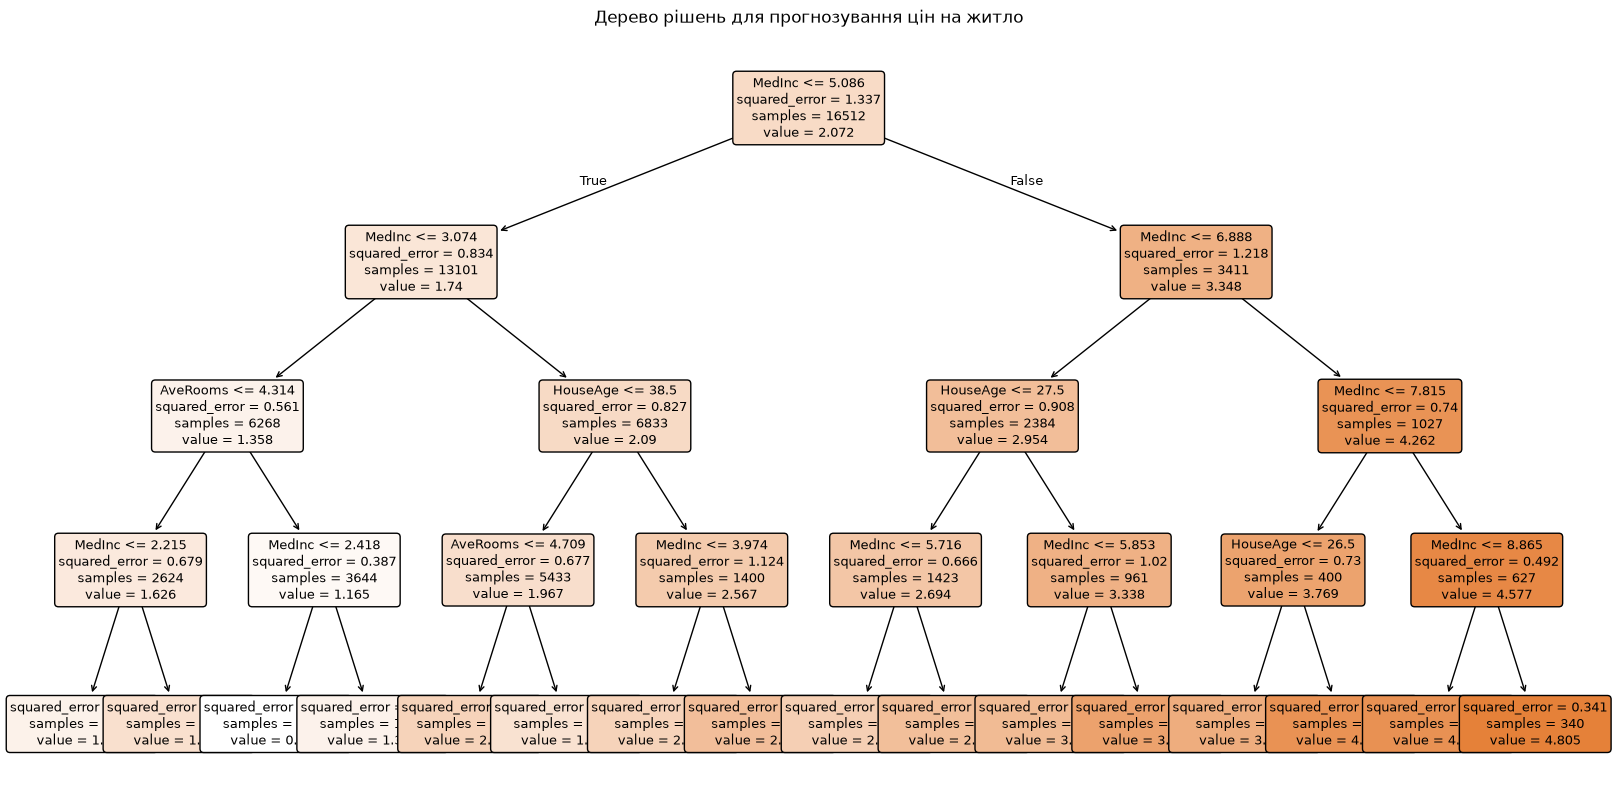

In [4]:
plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Дерево рішень для прогнозування цін на житло")
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()